In [1]:
#@title Import Library & Download Dataset

!pip install roboflow

from roboflow import Roboflow
import os
import hashlib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import userdata

api_key = userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=api_key)
project = rf.workspace("brad-dwyer").project("pothole-voxrl")
version = project.version(1)
dataset = version.download("tensorflow")

loading Roboflow workspace...
loading Roboflow project...


In [2]:
csv_path = os.path.join(dataset.location, "train", "_annotations.csv")
df_raw = pd.read_csv(csv_path)

print("Kolom asli bawaan Roboflow TensorFlow CSV:")
print(df_raw.columns.tolist())
display(df_raw.head(10))

Kolom asli bawaan Roboflow TensorFlow CSV:
['filename', 'width', 'height', 'class', 'xmin', 'ymin', 'xmax', 'ymax']


,filename,width,height,class,xmin,ymin,xmax,ymax
0,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,175,37,211,51
1,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,189,4,246,24
2,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,278,0,399,160
3,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,19,86,297,190
4,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,60,200,178,299
5,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,1,230,43,254
6,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,162,56,190,75
7,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,123,69,159,86
8,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,338,162,399,192
9,img-78_jpg.rf.01130ebf73370c115ee9de4fc1f29be5...,720,720,pothole,283,271,484,442


In [3]:
#@title Konfigurasi Direktori

sns.set_theme(style="whitegrid")
np.random.seed(42)

# Path folder dataset Pothole-1
BASE_DIR = "../content/Pothole-1"
FIGURES_DIR = "../content/reports/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

In [4]:
#@title Load & Gabungkan File _annotations.csv

splits = ["train", "valid", "test"]
df_list = []

for split in splits:
    csv_path = os.path.join(BASE_DIR, split, "_annotations.csv")
    if os.path.exists(csv_path):
        temp = pd.read_csv(csv_path)
        temp["split"] = split
        temp["filepath"] = temp["filename"].apply(
            lambda fname: os.path.join(BASE_DIR, split, fname)
        )
        df_list.append(temp)

df_raw = pd.concat(df_list, ignore_index=True)

print(f"Total baris anotasi (bounding box): {len(df_raw)}")
print(f"Total citra unik: {df_raw['filename'].nunique()}")
display(df_raw.head())

Total baris anotasi (bounding box): 1740
Total citra unik: 665


,filename,width,height,class,xmin,ymin,xmax,ymax,split,filepath
0,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,175,37,211,51,train,../content/Pothole-1/train/img-561_jpg.rf.00e5...
1,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,189,4,246,24,train,../content/Pothole-1/train/img-561_jpg.rf.00e5...
2,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,278,0,399,160,train,../content/Pothole-1/train/img-561_jpg.rf.00e5...
3,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,19,86,297,190,train,../content/Pothole-1/train/img-561_jpg.rf.00e5...
4,img-561_jpg.rf.00e55aff1b67a607a6631ac6a05bf7a...,400,300,pothole,60,200,178,299,train,../content/Pothole-1/train/img-561_jpg.rf.00e5...


In [5]:
#@title Inspeksi Kondisi Data

# 1. Missing Values & Kelengkapan File Citra
print("=== 1. MISSING VALUES ===")
print(df_raw.isnull().sum())
missing_files = df_raw[~df_raw["filepath"].apply(os.path.exists)]
print(f"File citra hilang di disk: {len(missing_files)}")

# 2. Validasi Koordinat Bounding Box
invalid_bbox = df_raw[(df_raw["xmax"] <= df_raw["xmin"]) | (df_raw["ymax"] <= df_raw["ymin"])]
print(f"\n=== 2. KOORDINAT INVALID ===\nJumlah bbox tidak valid: {len(invalid_bbox)}")

# 3. Pengecekan Duplikat Citra via MD5 Hash
def compute_md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

unique_files = df_raw[["filepath", "filename", "split"]].drop_duplicates().copy()
unique_files["md5"] = unique_files["filepath"].apply(compute_md5)
dup_count = unique_files["md5"].duplicated().sum()
print(f"\n=== 3. DUPLIKAT CITRA ===\nJumlah citra duplikat (MD5 sama): {dup_count}")

# 4. Statistik Rasio Luas Bounding Box & Deteksi Outlier
df_raw["bbox_area"] = (df_raw["xmax"] - df_raw["xmin"]) * (df_raw["ymax"] - df_raw["ymin"])
df_raw["img_area"] = df_raw["width"] * df_raw["height"]
df_raw["area_ratio"] = df_raw["bbox_area"] / df_raw["img_area"]

print("\n=== 4. STATISTIK AREA RATIO ===")
print(df_raw["area_ratio"].describe())
print(f"Outlier mikro (< 0.5% luas citra): {(df_raw['area_ratio'] < 0.005).sum()} bbox")
print(f"Outlier makro (> 15% luas citra): {(df_raw['area_ratio'] > 0.15).sum()} bbox")

=== 1. MISSING VALUES ===
filename    0
width       0
height      0
class       0
xmin        0
ymin        0
xmax        0
ymax        0
split       0
filepath    0
dtype: int64
File citra hilang di disk: 0

=== 2. KOORDINAT INVALID ===
Jumlah bbox tidak valid: 1

=== 3. DUPLIKAT CITRA ===
Jumlah citra duplikat (MD5 sama): 0

=== 4. STATISTIK AREA RATIO ===
count    1740.000000
mean        0.066369
std         0.116506
min         0.000000
25%         0.007154
50%         0.021400
75%         0.066054
max         0.852298
Name: area_ratio, dtype: float64
Outlier mikro (< 0.5% luas citra): 316 bbox
Outlier makro (> 15% luas citra): 206 bbox


In [6]:
#@title Agregasi Tingkat Citra & Pemetaan Target severity_label

# Agregasi per citra menggunakan rasio luas lubang terbesar (max_area_ratio)
df_img = (
    df_raw.groupby(["filepath", "filename", "split", "width", "height"], as_index=False)
    .agg(
        pothole_count=("class", "count"),
        max_area_ratio=("area_ratio", "max"),
        total_area_ratio=("area_ratio", "sum")
    )
)

def assign_severity(ratio):
    if ratio < 0.02:
        return "Low"
    elif ratio <= 0.07:
        return "Medium"
    else:
        return "Critical"

df_img["severity_label"] = df_img["max_area_ratio"].apply(assign_severity)

print("=== DISTRIBUSI KELAS KEPARAHAN ===")
dist = df_img["severity_label"].value_counts()
dist_pct = df_img["severity_label"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Jumlah": dist, "Persentase (%)": dist_pct.round(2)}))

print("\n=== DISTRIBUSI PER PARTISI (TRAIN / VALID / TEST) ===")
print(pd.crosstab(df_img["split"], df_img["severity_label"]))

=== DISTRIBUSI KELAS KEPARAHAN ===
                Jumlah  Persentase (%)
severity_label                        
Critical           378           56.84
Medium             247           37.14
Low                 40            6.02

=== DISTRIBUSI PER PARTISI (TRAIN / VALID / TEST) ===
severity_label  Critical  Low  Medium
split                                
test                  39    4      24
train                262   27     176
valid                 77    9      47


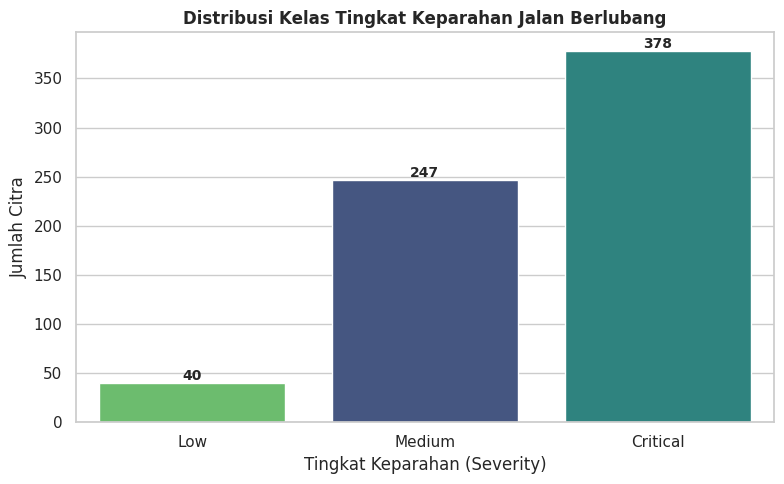

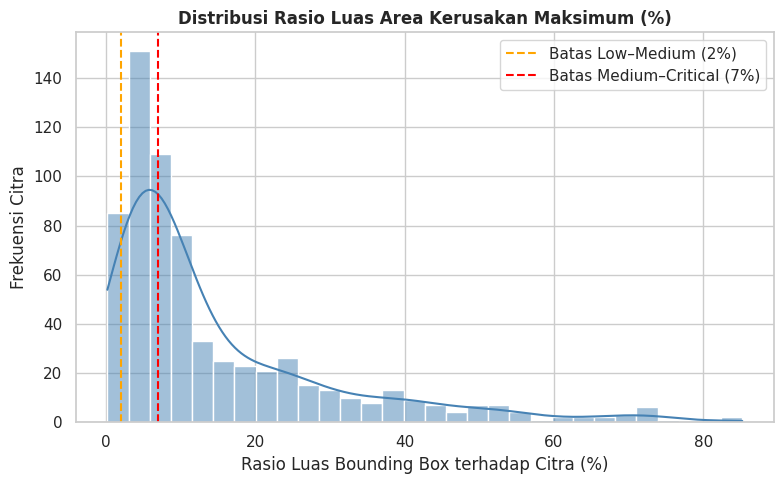

In [7]:
#@title Visualisasi 1 & 2 (Distribusi Kelas Keparahan & Rasio Luas Area)

order_cls = ["Low", "Medium", "Critical"]

# VISUALISASI 1: Distribusi Kelas Tingkat Keparahan
plt.figure(figsize=(8, 5))
ax1 = sns.countplot(
    data=df_img, x="severity_label", hue="severity_label",
    order=order_cls, palette="viridis", legend=False
)
plt.title("Distribusi Kelas Tingkat Keparahan Jalan Berlubang", fontsize=12, fontweight="bold")
plt.xlabel("Tingkat Keparahan (Severity)")
plt.ylabel("Jumlah Citra")
for p in ax1.patches:
    ax1.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom", fontsize=10, fontweight="bold"
    )
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "eda_01_class_distribution.png"), dpi=300)
plt.show()

# VISUALISASI 2: Distribusi Rasio Luas Bounding Box
plt.figure(figsize=(8, 5))
sns.histplot(df_img["max_area_ratio"] * 100, bins=30, kde=True, color="steelblue")
plt.axvline(2.0, color="orange", linestyle="--", label="Batas Low–Medium (2%)")
plt.axvline(7.0, color="red", linestyle="--", label="Batas Medium–Critical (7%)")
plt.title("Distribusi Rasio Luas Area Kerusakan Maksimum (%)", fontsize=12, fontweight="bold")
plt.xlabel("Rasio Luas Bounding Box terhadap Citra (%)")
plt.ylabel("Frekuensi Citra")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "eda_02_area_ratio_distribution.png"), dpi=300)
plt.show()

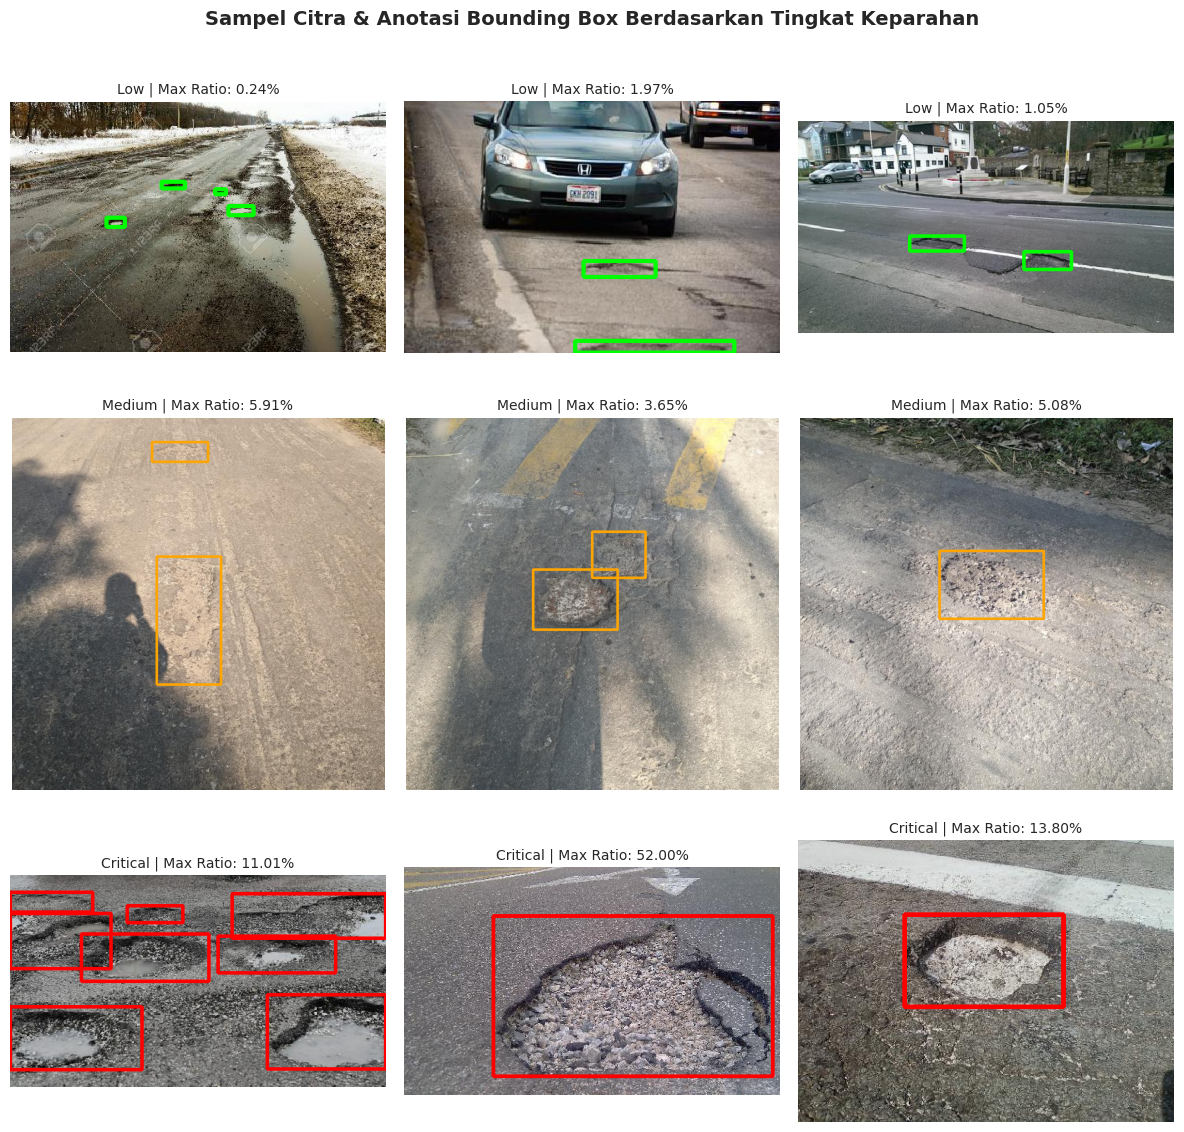

In [8]:
#@title Visualisasi 3 (Sampel Citra & Bounding Box per Kelas)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
colors = {"Low": (0, 255, 0), "Medium": (255, 165, 0), "Critical": (255, 0, 0)}

for row_idx, sev in enumerate(order_cls):
    subset = df_img[df_img["severity_label"] == sev]
    n_samples = min(3, len(subset))
    samples = subset.sample(n=n_samples, random_state=42)

    for col_idx, (_, row) in enumerate(samples.iterrows()):
        img = cv2.imread(row["filepath"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        bboxes = df_raw[df_raw["filepath"] == row["filepath"]]
        for _, b in bboxes.iterrows():
            cv2.rectangle(
                img,
                (int(b["xmin"]), int(b["ymin"])),
                (int(b["xmax"]), int(b["ymax"])),
                colors[sev],
                3
            )

        axes[row_idx, col_idx].imshow(img)
        axes[row_idx, col_idx].set_title(f"{sev} | Max Ratio: {row['max_area_ratio']*100:.2f}%", fontsize=10)
        axes[row_idx, col_idx].axis("off")

plt.suptitle("Sampel Citra & Anotasi Bounding Box Berdasarkan Tingkat Keparahan", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "eda_03_sample_images.png"), dpi=300)
plt.show()